In [2]:

from pathlib import Path
import pandas as pd

# ============================================================
# 1. Caminho da pasta
# ============================================================

pasta = Path(
    "/Users/claudiojacomassi/Documents/GitHub/"
    "Suicidio_adolescentes_Brasil/"
    "02_Tratamento_dados_database_PENSE_2024/"
    "02_Scripts_tratamento_dados_PENSE_2024"
)

# Arquivo original
arquivo_entrada = pasta / "07_PENSE2024_IDADE_13_A_17_CATEGORY.feather"

# Novo arquivo
arquivo_saida = pasta / "07_PENSE2024_IDADE_13_A_17_V_CRAMER_MAIORES_CORRELACOES"


# ============================================================
# 2. Variáveis a remover
# Código + nome completo da variável
# V de Cramér corrigido < 0,3
# ============================================================

variaveis_remover = {
    "E01P11802 - Quais tipos de suporte a escola oferece? - A escola conta com serviço terceirizado de profissional de saúde psicológica/mental",

    "E01P8505 - NOS ÚLTIMOS 12 MESES, a escola desenvolveu quais dessas seguintes ações? - Prevenção de violências e acidentes",

    "E01P11801 - Quais tipos de suporte a escola oferece? - A escola possui em seu quadro de funcionários profissional de saúde psicológica/mental",

    "B09016A1 - Alguma vez na vida alguém o(a) tocou, manipulou, beijou ou expôs partes do corpo contra a sua vontade?",

    "B09001 - NOS ÚLTIMOS 30 DIAS, em quantos dias você deixou de ir à escola porque não se sentia seguro NO CAMINHO de casa para a escola ou da escola para casa?",

    "B12008 - NOS ÚLTIMOS 30 DIAS, com que frequência você sentiu que a vida não vale a pena ser vivida?",

    "B12005 - NOS ÚLTIMOS 30 DIAS, com que frequência você se sentiu triste?",

    "B07011A - NOS ÚLTIMOS 30 DIAS, quantas vezes algum dos seus colegas de escola se recusou a falar com você, deixou você de lado sem razão ou fez com que outros colegas deixassem de falar com você?",

    "B07009 - NOS ÚLTIMOS 30 DIAS, você esculachou, zombou, mangou, intimidou ou caçoou algum(a) de seus(suas) colegas da escola tanto que ele(ela) ficou magoado(a), aborrecido(a), ofendido(a) ou humilhado(a)?"
}


# ============================================================
# 3. Ler o arquivo original
# ============================================================

if not arquivo_entrada.exists():
    raise FileNotFoundError(
        f"Arquivo original não encontrado:\n{arquivo_entrada}"
    )

df = pd.read_feather(arquivo_entrada)

print("BASE ORIGINAL")
print(f"Número de linhas: {df.shape[0]:,}")
print(f"Número de colunas: {df.shape[1]:,}")



# ============================================================
# 4. Identificar os nomes reais das colunas
# ============================================================

colunas_encontradas = []
colunas_nao_encontradas = []

for nome_documentado in variaveis_remover:

    # Extrair o código antes do primeiro " - "
    codigo = nome_documentado.split(" - ", 1)[0].strip()

    # Procurar a coluna pelo código ou pelo nome completo
    correspondencias = [
        coluna for coluna in df.columns
        if (
            str(coluna) == nome_documentado
            or str(coluna).startswith(codigo + " -")
            or str(coluna).startswith(codigo + " —")
            or str(coluna) == codigo
        )
    ]

    if correspondencias:
        coluna_real = correspondencias[0]

        if coluna_real not in colunas_encontradas:
            colunas_encontradas.append(coluna_real)

        print(f"\nENCONTRADA: {codigo}")
        print(f"Nome da coluna: {coluna_real}")

    else:
        colunas_nao_encontradas.append(
            (codigo, nome_documentado)
        )

        print(f"\nNÃO ENCONTRADA: {codigo}")
        print(f"Descrição esperada: {nome_documentado}")



# ============================================================
# 5. Remover as colunas encontradas
# ============================================================

df_filtrado = df.drop(columns=colunas_encontradas)


# ============================================================
# 6. Salvar o novo arquivo Feather
# ============================================================

df_filtrado.reset_index(drop=True).to_feather(arquivo_saida)


# ============================================================
# 7. Verificar o resultado
# ============================================================

df_verificacao = pd.read_feather(arquivo_saida)

print("\n" + "=" * 60)
print("RESULTADO FINAL")
print("=" * 60)

print(f"Linhas originais: {df.shape[0]:,}")
print(f"Colunas originais: {df.shape[1]:,}")
print(f"Colunas removidas: {len(colunas_encontradas)}")
print(f"Linhas finais: {df_verificacao.shape[0]:,}")
print(f"Colunas finais: {df_verificacao.shape[1]:,}")

print("\nArquivo gravado em:")
print(arquivo_saida)

print(
    f"\nTamanho do arquivo: "
    f"{arquivo_saida.stat().st_size / (1024**2):.2f} MB"
)

if colunas_nao_encontradas:
    print("\nATENÇÃO — códigos não encontrados:")
    for codigo in colunas_nao_encontradas:
        print(f"- {codigo}")
else:
    print("\nTodas as colunas foram encontradas e removidas.")

# Confirmar que B12009 continua na base
if "B12009" in df_verificacao.columns or any(
    str(c).startswith("B12009 -")
    or str(c).startswith("B12009 —")
    for c in df_verificacao.columns
):
    print("A variável-alvo B12009 foi preservada.")
else:
    print("ATENÇÃO: confira se B12009 está presente na base.")


BASE ORIGINAL
Número de linhas: 118,036
Número de colunas: 39

ENCONTRADA: B12008
Nome da coluna: B12008 - NOS ÚLTIMOS 30 DIAS, com que frequência você sentiu que a vida não vale a pena ser vivida?

ENCONTRADA: B09016A1
Nome da coluna: B09016A1 - Alguma vez na vida alguém o(a) tocou, manipulou, beijou ou expôs partes do corpo contra a sua vontade?

ENCONTRADA: B12005
Nome da coluna: B12005 - NOS ÚLTIMOS 30 DIAS, com que frequência você se sentiu triste?

ENCONTRADA: B07011A
Nome da coluna: B07011A - NOS ÚLTIMOS 30 DIAS, quantas vezes algum dos seus colegas de escola se recusou a falar com você, deixou você de lado sem razão ou fez com que outros colegas deixassem de falar com você?

ENCONTRADA: E01P11801
Nome da coluna: E01P11801 - Quais tipos de suporte a escola oferece? - A escola possui em seu quadro de funcionários profissional de saúde psicológica/mental

ENCONTRADA: B09001
Nome da coluna: B09001 - NOS ÚLTIMOS 30 DIAS, em quantos dias você deixou de ir à escola porque não se senti

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 118036 entries, 0 to 118035
Data columns (total 39 columns):
 #   Column                                                                                                                                                                                                                                                   Non-Null Count   Dtype   
---  ------                                                                                                                                                                                                                                                   --------------   -----   
 0   CAPITAL - indica se é município da capital                                                                                                                                                                                                               118036 non-null  category
 1   B01001A - Qual é o seu sexo?                

In [5]:
# ============================================================
# CÉLULA 0 — ESCOLHA DOS PARÂMETROS (OBRIGATÓRIO)
# Confira/altere os valores e clique em "Confirmar parâmetros".
# REGRESSÃO LOGÍSTICA — BASE FILTRADA POR V DE CRAMÉR (>= 0,3)
# ============================================================

import ipywidgets as widgets
from IPython.display import display, clear_output

_penalty = widgets.Dropdown(
    options=[
        ('L2 (padrão atual)', 'l2'),
        ('L1', 'l1'),
        ('Sem regularização', 'none')
    ],
    value='l2',
    description='Penalty:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='420px')
)

_C = widgets.Dropdown(
    options=[
        ('0.01 — regularização forte', 0.01),
        ('0.1', 0.1),
        ('1.0 — padrão', 1.0),
        ('10', 10.0),
        ('100 — regularização fraca', 100.0)
    ],
    value=1.0,
    description='C (regularização):',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='420px')
)

_max_iter = widgets.BoundedIntText(
    value=2000, min=1, max=100000, step=100,
    description='Max iter:',
    style={'description_width': 'initial'}
)

_random_state = widgets.IntText(
    value=42,
    description='Random state:',
    style={'description_width': 'initial'}
)

_test_size = widgets.Dropdown(
    options=[
        ('10% teste / 90% treino', 0.10),
        ('20% teste / 80% treino (atual)', 0.20),
        ('25% teste / 75% treino', 0.25),
        ('30% teste / 70% treino', 0.30),
        ('40% teste / 60% treino', 0.40)
    ],
    value=0.20,
    description='Divisão treino/teste:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='420px')
)

_confirmar = widgets.Button(
    description='Confirmar parâmetros',
    button_style='success',
    icon='check'
)
_status = widgets.Output()
_PARAMETROS_CONFIRMADOS = False

_painel = widgets.VBox([
    widgets.HTML('<h3>Configuração da regressão logística — PeNSE 2024</h3>'),
    widgets.HTML(
        '<p>Base filtrada por V de Cramér. Os valores atuais já estão '
        'selecionados. Confirme-os ou escolha outros antes do treinamento.</p>'
    ),
    _penalty, _C, _max_iter, _random_state, _test_size,
    _confirmar, _status
], layout=widgets.Layout(
    border='1px solid #cccccc',
    padding='12px',
    width='500px'
))

def _confirmar_parametros(_):
    global PENALTY, C, MAX_ITER, RANDOM_STATE, TEST_SIZE, SOLVER
    global _PARAMETROS_CONFIRMADOS

    with _status:
        clear_output(wait=True)

        PENALTY = None if _penalty.value == 'none' else _penalty.value
        C = float(_C.value)
        MAX_ITER = int(_max_iter.value)
        RANDOM_STATE = int(_random_state.value)
        TEST_SIZE = float(_test_size.value)

        # liblinear aceita L1 e L2; lbfgs é utilizado para L2
        # e para o modelo sem regularização.
        SOLVER = 'liblinear' if PENALTY == 'l1' else 'lbfgs'

        _PARAMETROS_CONFIRMADOS = True

        print('Parâmetros confirmados:')
        print(f'  penalty={PENALTY!r}')
        print(f'  C={C}')
        print(f'  max_iter={MAX_ITER}')
        print(f'  random_state={RANDOM_STATE}')
        print(f'  treino/teste={1-TEST_SIZE:.0%}/{TEST_SIZE:.0%}')
        print(f'  solver={SOLVER!r}')
        if PENALTY is None:
            print('  Observação: C não tem efeito sem regularização.')
        print('Agora execute a célula de treinamento (Célula 1).')

_confirmar.on_click(_confirmar_parametros)
display(_painel)


DESFECHO: 0 = Não (código original 1); 1 = Sim (código original 3)

Distribuição do desfecho na base utilizável:


,Quantidade,Percentual
0,,
Não (0),78786,67.139339
Sim (1),38561,32.860661


Registros utilizáveis: 117,347
Preditores categóricos utilizados: 29
Hiperparâmetros utilizados no treinamento:
  penalty='l2'
  C=1.0
  max_iter=2000
  solver='lbfgs'
  random_state=42
  treino/teste=80%/20%

MÉTRICAS DO TREINO


,Treino (80%)
Acurácia,0.7512
Precisão (Sim),0.6706
Sensibilidade / Recall (Sim),0.4775
Especificidade (Não),0.8852
Valor preditivo negativo,0.7759
F1-score (Sim),0.5578
AUC-ROC,0.7911
Average Precision,0.6551
Brier score (menor é melhor),0.1682



Relatório de classificação — treino:
              precision    recall  f1-score   support

     Não (0)       0.78      0.89      0.83     63028
     Sim (1)       0.67      0.48      0.56     30849

    accuracy                           0.75     93877
   macro avg       0.72      0.68      0.69     93877
weighted avg       0.74      0.75      0.74     93877



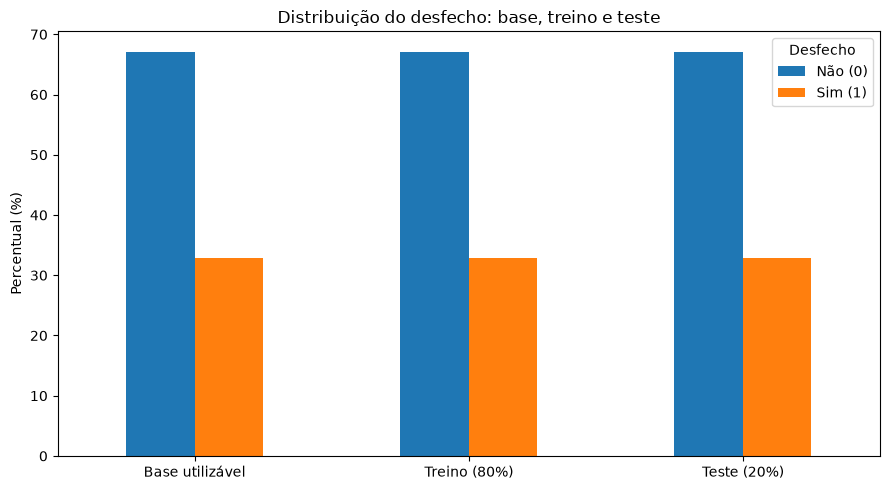

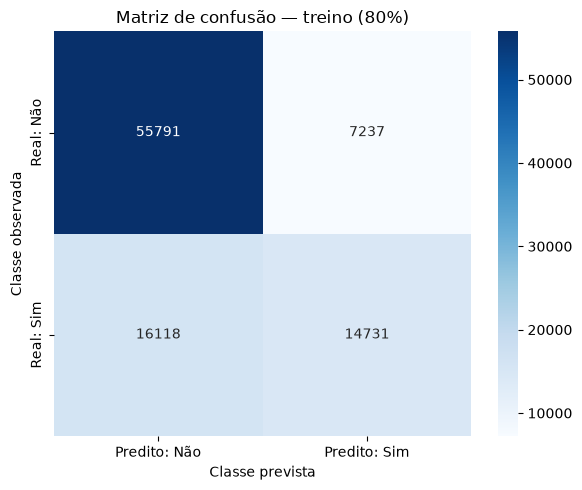

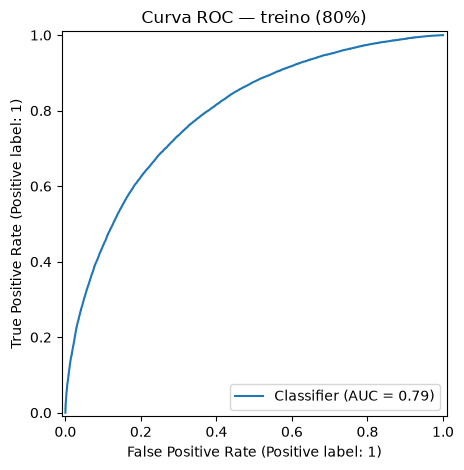

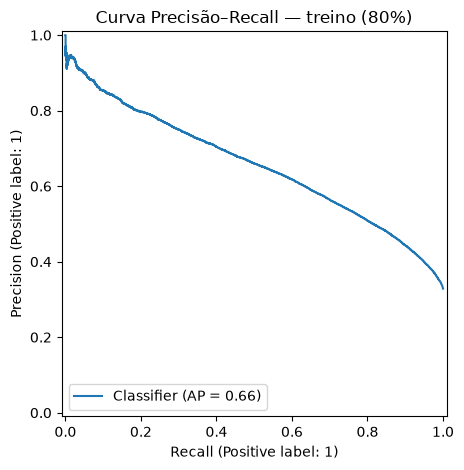

Average Precision no treino: 0.6551


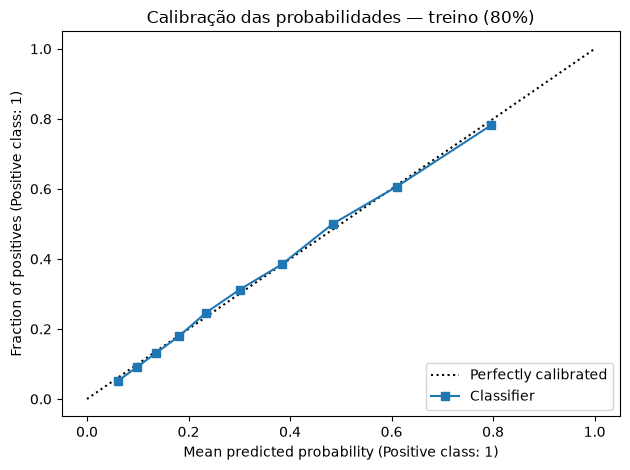

Brier score no treino (menor é melhor): 0.1682

30 categorias com maiores coeficientes absolutos:


,Categoria/preditor,Coeficiente_log_odds,Odds_ratio
49,"categoricas__B12006 - NOS ÚLTIMOS 30 DIAS, com que frequência você sentiu que ninguém se preocupa com você?_3",0.7746,2.1697
1,categoricas__B01001A - Qual é o seu sexo?_2,0.7276,2.0702
54,"categoricas__B09002 - NOS ÚLTIMOS 30 DIAS, em quantos dias você não foi à escola porque não se sentia seguro NA ESCOLA?_3",0.5656,1.7604
60,"categoricas__B09016A2 - Alguma vez na vida alguém ameaçou, intimidou ou obrigou a ter relações sexuais ou qualquer outro ato sexual contra a sua vontade?_3",0.5254,1.6912
52,"categoricas__B12007 - NOS ÚLTIMOS 30 DIAS, com que frequência você se sentiu irritado(a), nervoso(a) ou mal-humorado(a) por qualquer coisa?_3",0.4550,1.5762
20,categoricas__B05002A - Alguma vez na vida você tomou um copo ou uma dose de bebida alcoólica?_1,-0.3944,0.6741
25,"categoricas__B07004 - NOS ÚLTIMOS 30 DIAS, com que frequência sua mãe, pai ou responsável entendeu suas preocupações e problemas?_1",0.3688,1.4460
48,"categoricas__B12006 - NOS ÚLTIMOS 30 DIAS, com que frequência você sentiu que ninguém se preocupa com você?_2",0.3197,1.3767
39,"categoricas__B07013 - NOS ÚLTIMOS 30 DIAS, você se sentiu ameaçado(a), ofendido(a) ou humilhado(a) nas redes sociais ou aplicativos de celular?_3",0.3121,1.3662
58,"categoricas__B09010A1 - NOS ÚLTIMOS 12 MESES, quantas vezes você foi agredido(a) fisicamente por OUTRA PESSOA que não seja sua mãe, pai ou responsável?_3",0.3094,1.3625


/var/folders/6q/rl1jn5t52qg9qxc6f3l113480000gn/T/ipykernel_24209/633208183.py:244: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


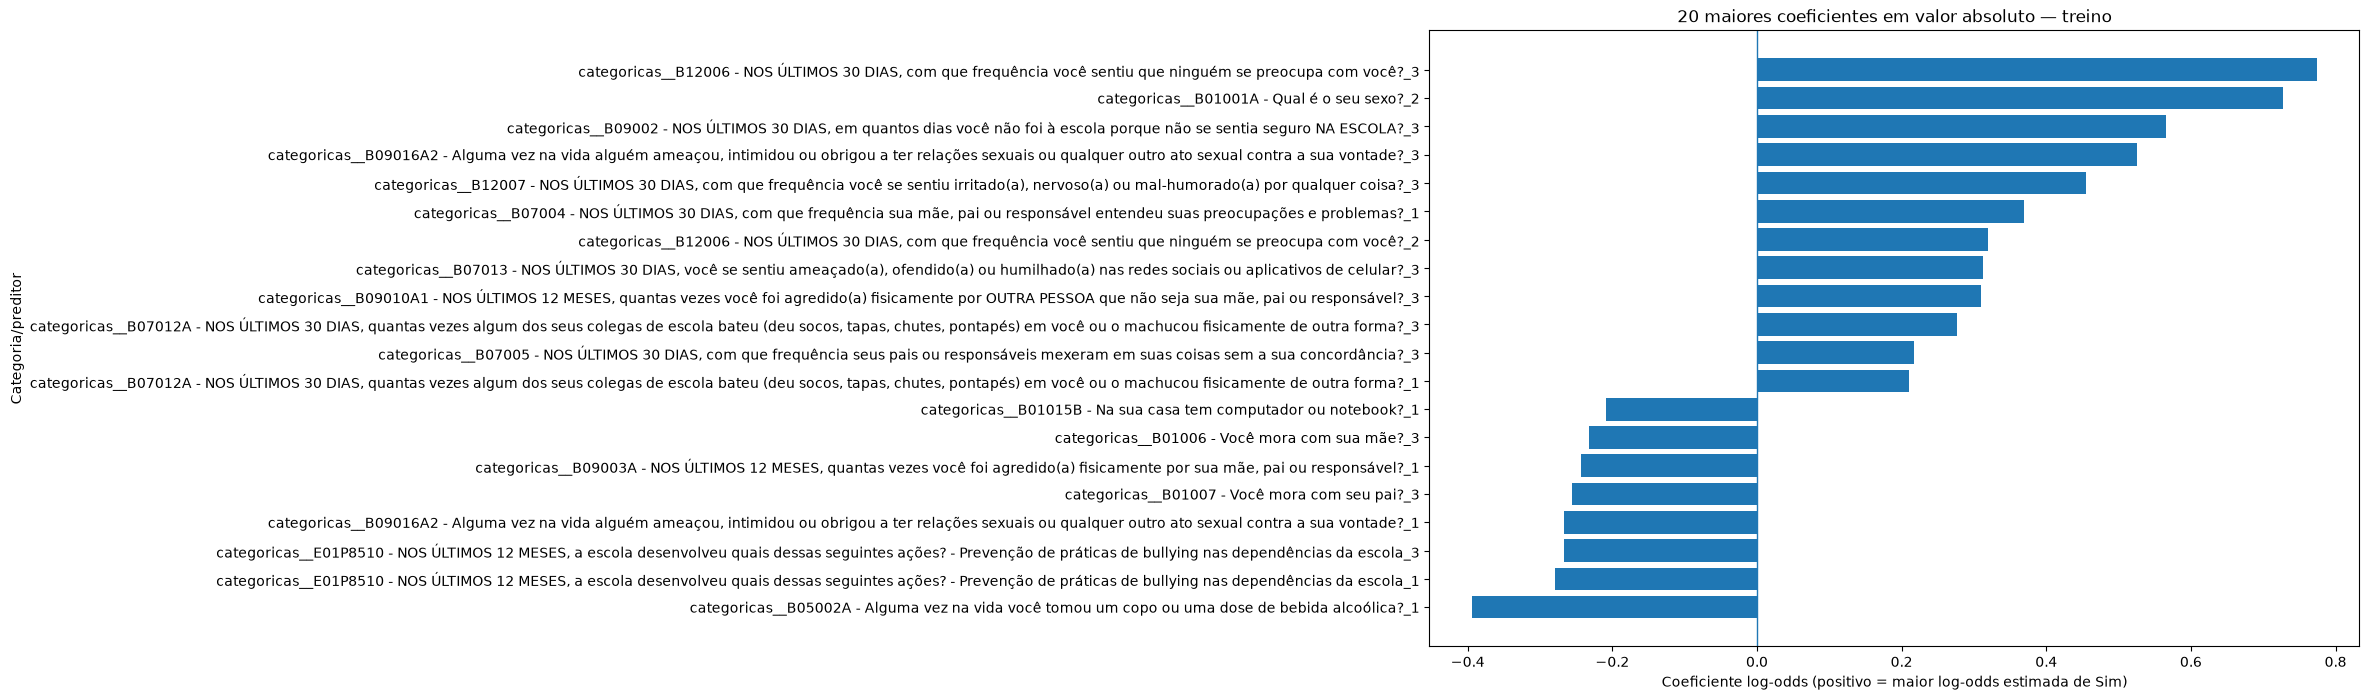


Nota: os gráficos e métricas do treino descrevem o ajuste aos dados usados para estimar o modelo e tendem a ser otimistas. A avaliação final deve ser feita na CÉLULA 2, usando os 20% reservados. Coeficientes/odds ratios são associações ajustadas, não demonstram causalidade e não incluem intervalos de confiança nesta análise.


In [7]:
# ============================================================
# CÉLULA 1 — REGRESSÃO LOGÍSTICA COM BASE FILTRADA POR V DE CRAMÉR
# ============================================================

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score,
    RocCurveDisplay, PrecisionRecallDisplay, average_precision_score,
    brier_score_loss
)
from sklearn.calibration import CalibrationDisplay

warnings.filterwarnings("ignore", category=FutureWarning)


# ============================================================
# PARÂMETROS definidos na Célula 0 pela tabela interativa
# ============================================================
if not globals().get("_PARAMETROS_CONFIRMADOS", False):
    raise RuntimeError(
        "Antes de treinar, execute a Célula 0 e clique em 'Confirmar parâmetros'."
    )

# Caminho da base de entrada (.feather)
ARQUIVO = "/Users/claudiojacomassi/Documents/GitHub/Suicidio_adolescentes_Brasil/02_Tratamento_dados_database_PENSE_2024/02_Scripts_tratamento_dados_PENSE_2024/07_PENSE2024_IDADE_13_A_17_V_CRAMER_MAIORES_CORRELACOES"

# Desfecho: códigos originais esperados 1 = Não e 3 = Sim
TARGET = "B12009 - NOS ÚLTIMOS 12 MESES, alguma vez você sentiu vontade de se machucar de propósito?"

if not os.path.exists(ARQUIVO):
    raise FileNotFoundError(
        f"Arquivo não encontrado: {ARQUIVO}\n"
        "Atualize a variável ARQUIVO para o caminho correto no seu computador."
    )

df = pd.read_feather(ARQUIVO)
if TARGET not in df.columns:
    raise ValueError(
        f"TARGET não encontrado: {TARGET}\n"
        "Confira o nome exato da coluna no arquivo."
    )

# Conforme solicitado, assumir todas as colunas como categóricas.
dados = df.copy()
for coluna in dados.columns:
    dados[coluna] = dados[coluna].astype("category")

# Remover linhas sem desfecho observado.
dados = dados.loc[dados[TARGET].notna()].copy()

# Recodificação explícita do desfecho: 1 = Não -> 0; 3 = Sim -> 1.
codigo_target = pd.to_numeric(
    dados[TARGET].astype("string").str.extract(r"(\d+)")[0],
    errors="coerce"
)
validos = codigo_target.isin([1, 3])
dados = dados.loc[validos].copy()
codigo_target = codigo_target.loc[validos]
y = codigo_target.map({1: 0, 3: 1}).astype("int64")
X = dados.drop(columns=[TARGET]).astype("object")

# Remover preditores sem valores ou constantes.
colunas_validas = [
    c for c in X.columns
    if X[c].notna().any() and X[c].nunique(dropna=True) > 1
]
X = X[colunas_validas]

if X.shape[1] == 0:
    raise ValueError("Não restaram variáveis preditoras válidas.")
if y.nunique() != 2:
    raise ValueError(
        "Após a recodificação, não há as duas classes esperadas. "
        "Confira os rótulos/códigos da variável TARGET."
    )

print("DESFECHO: 0 = Não (código original 1); 1 = Sim (código original 3)")
print("\nDistribuição do desfecho na base utilizável:")
display(
    y.value_counts().reindex([0, 1], fill_value=0)
    .rename(index={0: "Não (0)", 1: "Sim (1)"})
    .to_frame("Quantidade")
    .assign(Percentual=lambda t: 100 * t["Quantidade"] / len(y))
)
print(f"Registros utilizáveis: {len(y):,}")
print(f"Preditores categóricos utilizados: {X.shape[1]:,}")

# Separar 80% treino / 20% teste antes do pré-processamento para evitar vazamento.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)

# Imputação pela categoria mais frequente + One-Hot Encoding.
preprocessador = ColumnTransformer(
    transformers=[
        ("categoricas", Pipeline([
            ("imputacao", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore"))
        ]), X.columns.tolist())
    ],
    remainder="drop"
)

modelo = Pipeline([
    ("preprocessamento", preprocessador),
    ("regressao", LogisticRegression(
        penalty=PENALTY,
        C=C,
        max_iter=MAX_ITER,
        random_state=RANDOM_STATE,
        solver=SOLVER
    ))
])

print("Hiperparâmetros utilizados no treinamento:")
print(f"  penalty={PENALTY!r}")
print(f"  C={C}")
print(f"  max_iter={MAX_ITER}")
print(f"  solver={SOLVER!r}")
print(f"  random_state={RANDOM_STATE}")
print(f"  treino/teste={1-TEST_SIZE:.0%}/{TEST_SIZE:.0%}")

modelo.fit(X_train, y_train)

# Métricas no treino
y_train_pred = modelo.predict(X_train)
y_train_prob = modelo.predict_proba(X_train)[:, 1]

def calcular_metricas(y_real, y_pred, y_prob):
    return {
        "Acurácia": accuracy_score(y_real, y_pred),
        "Precisão (Sim)": precision_score(y_real, y_pred, zero_division=0),
        "Sensibilidade / Recall (Sim)": recall_score(y_real, y_pred, zero_division=0),
        "Especificidade (Não)": (
            confusion_matrix(y_real, y_pred, labels=[0, 1])[0, 0] /
            max(confusion_matrix(y_real, y_pred, labels=[0, 1])[0].sum(), 1)
        ),
        "Valor preditivo negativo": (
            confusion_matrix(y_real, y_pred, labels=[0, 1])[0, 0] /
            max(confusion_matrix(y_real, y_pred, labels=[0, 1])[:, 0].sum(), 1)
        ),
        "F1-score (Sim)": f1_score(y_real, y_pred, zero_division=0),
        "AUC-ROC": roc_auc_score(y_real, y_prob) if pd.Series(y_real).nunique() == 2 else np.nan,
        "Average Precision": average_precision_score(y_real, y_prob),
        "Brier score (menor é melhor)": brier_score_loss(y_real, y_prob)
    }

metricas_treino = pd.DataFrame.from_dict(
    calcular_metricas(y_train, y_train_pred, y_train_prob),
    orient="index", columns=[f"Treino ({1-TEST_SIZE:.0%})"]
)
print("\nMÉTRICAS DO TREINO")
display(metricas_treino.style.format("{:.4f}"))

print("\nRelatório de classificação — treino:")
print(classification_report(
    y_train, y_train_pred, labels=[0, 1],
    target_names=["Não (0)", "Sim (1)"], zero_division=0
))

# Distribuição das classes na base completa, treino e teste
dist = []
for nome, serie in [("Base utilizável", y), (f"Treino ({1-TEST_SIZE:.0%})", y_train), (f"Teste ({TEST_SIZE:.0%})", y_test)]:
    pct = serie.value_counts(normalize=True).reindex([0, 1], fill_value=0) * 100
    dist.append({"Conjunto": nome, "Não (0)": pct[0], "Sim (1)": pct[1]})
dist_df = pd.DataFrame(dist).set_index("Conjunto")
ax = dist_df.plot(kind="bar", figsize=(9, 5))
ax.set_title("Distribuição do desfecho: base, treino e teste")
ax.set_ylabel("Percentual (%)")
ax.set_xlabel("")
ax.legend(title="Desfecho")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Matriz de confusão — treino
cm_train = confusion_matrix(y_train, y_train_pred, labels=[0, 1])
plt.figure(figsize=(6, 5))
sns.heatmap(cm_train, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Predito: Não", "Predito: Sim"],
            yticklabels=["Real: Não", "Real: Sim"])
plt.title(f"Matriz de confusão — treino ({1-TEST_SIZE:.0%})")
plt.xlabel("Classe prevista")
plt.ylabel("Classe observada")
plt.tight_layout()
plt.show()

# Curva ROC — treino
RocCurveDisplay.from_predictions(y_train, y_train_prob)
plt.title(f"Curva ROC — treino ({1-TEST_SIZE:.0%})")
plt.tight_layout()
plt.show()

# Curva Precisão–Recall — treino
PrecisionRecallDisplay.from_predictions(y_train, y_train_prob)
plt.title(f"Curva Precisão–Recall — treino ({1-TEST_SIZE:.0%})")
plt.tight_layout()
plt.show()
print("Average Precision no treino:", f"{average_precision_score(y_train, y_train_prob):.4f}")

# Calibração — treino (avalia se probabilidade prevista combina com frequência observada)
CalibrationDisplay.from_predictions(y_train, y_train_prob, n_bins=10, strategy="quantile")
plt.title(f"Calibração das probabilidades — treino ({1-TEST_SIZE:.0%})")
plt.tight_layout()
plt.show()
print("Brier score no treino (menor é melhor):", f"{brier_score_loss(y_train, y_train_prob):.4f}")

# Coeficientes e odds ratios das categorias geradas pelo One-Hot Encoding.
nomes_features = modelo.named_steps["preprocessamento"].get_feature_names_out()
coef = modelo.named_steps["regressao"].coef_[0]
coeficientes = pd.DataFrame({
    "Categoria/preditor": nomes_features,
    "Coeficiente_log_odds": coef,
    "Odds_ratio": np.exp(coef)
})
coeficientes["Abs_coeficiente"] = coeficientes["Coeficiente_log_odds"].abs()
coeficientes = coeficientes.sort_values("Abs_coeficiente", ascending=False)

print("\n30 categorias com maiores coeficientes absolutos:")
display(coeficientes.head(30).drop(columns="Abs_coeficiente").style.format({
    "Coeficiente_log_odds": "{:.4f}", "Odds_ratio": "{:.4f}"
}))

top20 = coeficientes.head(20).sort_values("Coeficiente_log_odds")
plt.figure(figsize=(12, 8))
plt.barh(top20["Categoria/preditor"], top20["Coeficiente_log_odds"])
plt.axvline(0, linewidth=1)
plt.title("20 maiores coeficientes em valor absoluto — treino")
plt.xlabel("Coeficiente log-odds (positivo = maior log-odds estimada de Sim)")
plt.ylabel("Categoria/preditor")
plt.tight_layout()
plt.show()

print(
    "\nNota: os gráficos e métricas do treino descrevem o ajuste aos dados usados "
    "para estimar o modelo e tendem a ser otimistas. A avaliação final deve ser "
    "feita na CÉLULA 2, usando os 20% reservados. Coeficientes/odds ratios são "
    "associações ajustadas, não demonstram causalidade e não incluem intervalos "
    "de confiança nesta análise."
)


In [5]:
#Gera um array sequencial para cada feature e a importancia deles seria as maiores nao importando se e negativo ou positivo (como foi realizado one-hot encoding o array contem quase 100 plus features ao invest de 38 features originatis)
modelo["regressao"].coef_

array([[-0.55267842, -0.25215363,  0.04830291,  0.02781438, -0.08666583,
         0.2520556 ,  0.1128038 , -0.06225372, -0.00392292,  0.05654598,
         0.06619063, -0.09584879, -0.09585856, -0.03112762, -0.14983483,
        -0.00702297, -0.12917613,  0.06761276,  0.32470942,  0.33252294,
        -0.14105991,  0.25045273, -0.07202464, -0.19337929, -0.2948692 ,
        -0.12729301, -0.03728594, -0.20823656, -0.09198512, -0.08285041,
         0.04218452, -0.36793065,  0.25529828,  0.67374242,  0.21362896,
         0.3937431 ,  0.47416193,  0.00575769,  0.18054324,  0.35238369,
        -0.36519241,  0.61167288,  1.06084926, -0.03792842, -0.17035757,
         0.26540315,  0.51386899, -0.29984276, -0.03006111,  0.32269682,
         0.50818476, -0.50692386,  0.14827681, -0.00580419,  0.43513977]])

In [6]:
modelo["regressao"]

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'l2'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",2000
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the opti

COMPARAÇÃO DO DESEMPENHO: TREINO VS. TESTE


,Treino (80%),Teste (20%),Diferença (teste - treino)
Acurácia,0.7512,0.7481,-0.0031
Precisão (Sim),0.6706,0.6607,-0.0099
Sensibilidade / Recall (Sim),0.4775,0.4802,0.0026
Especificidade (Não),0.8852,0.8793,-0.0059
Valor preditivo negativo,0.7759,0.7756,-0.0003
F1-score (Sim),0.5578,0.5561,-0.0017
AUC-ROC,0.7911,0.7858,-0.0053
Average Precision,0.6551,0.6449,-0.0102
Brier score (menor é melhor),0.1682,0.1704,0.0022



Relatório de classificação — teste:
              precision    recall  f1-score   support

     Não (0)       0.78      0.88      0.82     15758
     Sim (1)       0.66      0.48      0.56      7712

    accuracy                           0.75     23470
   macro avg       0.72      0.68      0.69     23470
weighted avg       0.74      0.75      0.74     23470


INTERVALOS DE CONFIANÇA DE 95% — BOOTSTRAP NO TESTE


,Métrica,Estimativa no teste,IC 95% inferior,IC 95% superior
0,Acurácia,0.7481,0.7432,0.7535
1,Precisão (Sim),0.6607,0.6486,0.6723
2,Sensibilidade / Recall (Sim),0.4802,0.4699,0.4914
3,Especificidade (Não),0.8793,0.8744,0.8841
4,F1-score (Sim),0.5561,0.5466,0.5659
5,AUC-ROC,0.7858,0.7798,0.7917
6,Average Precision,0.6449,0.6337,0.6557


Nota: intervalos por bootstrap simples; não consideram pesos, estratos ou conglomerados do desenho amostral da PeNSE.


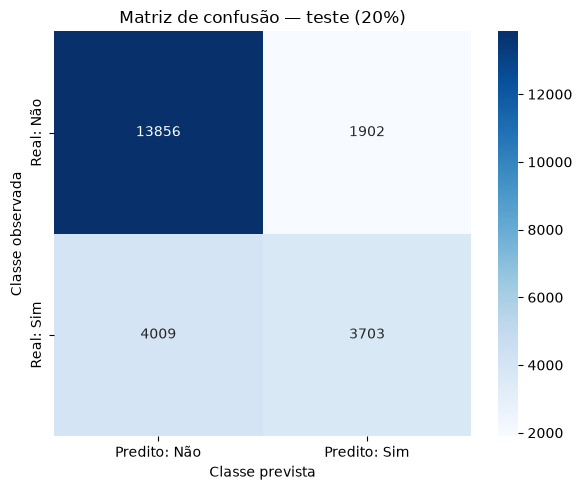

<Figure size 700x600 with 0 Axes>

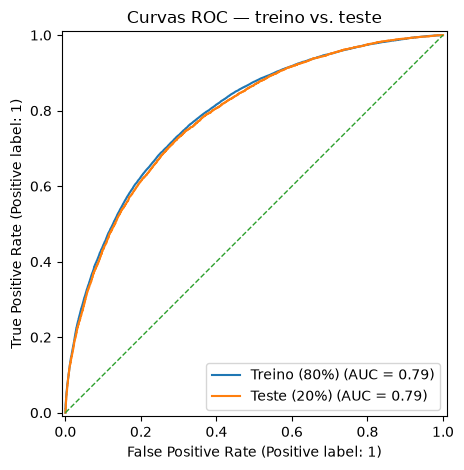

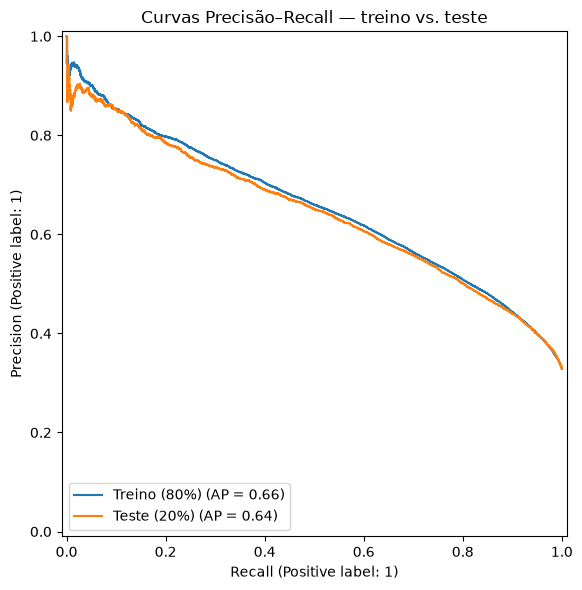

Average Precision — teste: 0.6449


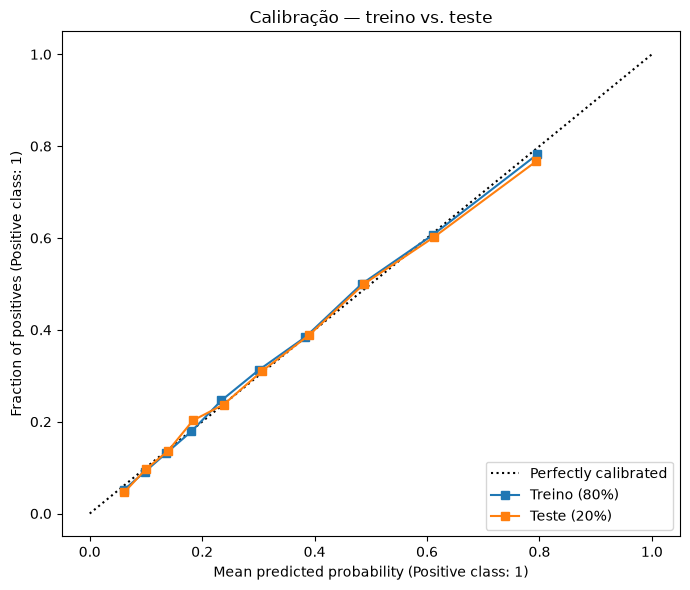

Brier score — treino: 0.1682
Brier score — teste:  0.1704
Brier score menor indica probabilidades mais próximas dos resultados observados, em média.


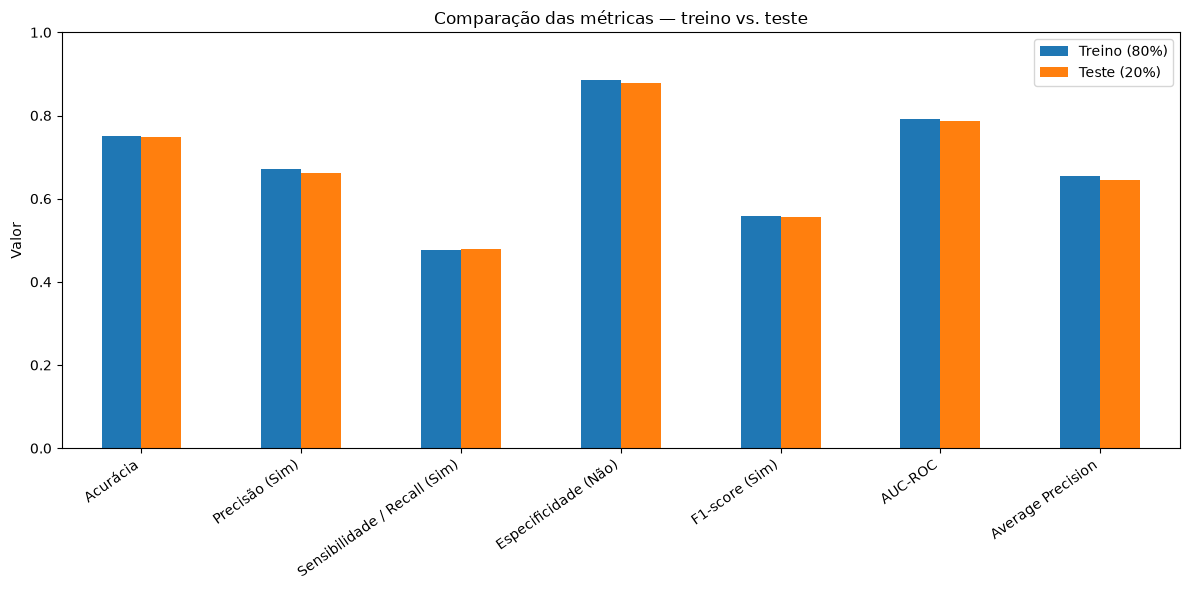


INTERPRETAÇÃO: diferenças grandes entre treino e teste podem indicar sobreajuste ou mudança de distribuição. A avaliação final deve considerar especialmente sensibilidade, precisão, AUC-ROC, Average Precision e calibração. O limiar padrão de 0,5 foi mantido; para aplicações sensíveis, ele deve ser escolhido com critérios explícitos usando dados de validação, não o teste final.


In [8]:
# ============================================================
# CÉLULA 2 — AVALIAÇÃO FINAL NO TESTE E COMPARAÇÃO COM TREINO
# ============================================================

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score,
    RocCurveDisplay, PrecisionRecallDisplay, average_precision_score,
    brier_score_loss
)
from sklearn.calibration import CalibrationDisplay

# Predições no conjunto de teste (que não foi usado para ajustar o modelo)
y_test_pred = modelo.predict(X_test)
y_test_prob = modelo.predict_proba(X_test)[:, 1]

# Recalcular métricas comparáveis para treino e teste.
y_train_pred = modelo.predict(X_train)
y_train_prob = modelo.predict_proba(X_train)[:, 1]

def metricas_avaliacao(y_real, y_pred, y_prob):
    cm = confusion_matrix(y_real, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    return {
        "Acurácia": accuracy_score(y_real, y_pred),
        "Precisão (Sim)": precision_score(y_real, y_pred, zero_division=0),
        "Sensibilidade / Recall (Sim)": recall_score(y_real, y_pred, zero_division=0),
        "Especificidade (Não)": tn / (tn + fp) if (tn + fp) else np.nan,
        "Valor preditivo negativo": tn / (tn + fn) if (tn + fn) else np.nan,
        "F1-score (Sim)": f1_score(y_real, y_pred, zero_division=0),
        "AUC-ROC": roc_auc_score(y_real, y_prob) if pd.Series(y_real).nunique() == 2 else np.nan,
        "Average Precision": average_precision_score(y_real, y_prob),
        "Brier score (menor é melhor)": brier_score_loss(y_real, y_prob)
    }

m_treino = metricas_avaliacao(y_train, y_train_pred, y_train_prob)
m_teste = metricas_avaliacao(y_test, y_test_pred, y_test_prob)

comparacao = pd.DataFrame({
    f"Treino ({1-TEST_SIZE:.0%})": pd.Series(m_treino),
    f"Teste ({TEST_SIZE:.0%})": pd.Series(m_teste)
})
comparacao["Diferença (teste - treino)"] = comparacao[f"Teste ({TEST_SIZE:.0%})"] - comparacao[f"Treino ({1-TEST_SIZE:.0%})"]

print("COMPARAÇÃO DO DESEMPENHO: TREINO VS. TESTE")
display(comparacao.style.format("{:.4f}"))

print("\nRelatório de classificação — teste:")
print(classification_report(
    y_test, y_test_pred, labels=[0, 1],
    target_names=["Não (0)", "Sim (1)"], zero_division=0
))

# Intervalos de confiança de 95% por bootstrap no conjunto de teste.
# Bootstrap simples por linha; pressupõe observações independentes e não
# incorpora o desenho amostral complexo da PeNSE.
rng = np.random.default_rng(RANDOM_STATE)
B = 1000
metricas_boot = {
    "Acurácia": [],
    "Precisão (Sim)": [],
    "Sensibilidade / Recall (Sim)": [],
    "Especificidade (Não)": [],
    "F1-score (Sim)": [],
    "AUC-ROC": [],
    "Average Precision": []
}

yt = np.asarray(y_test)
yp = np.asarray(y_test_pred)
yb = np.asarray(y_test_prob)
n = len(yt)

for _ in range(B):
    idx = rng.integers(0, n, size=n)
    yt_b, yp_b, yb_b = yt[idx], yp[idx], yb[idx]
    cm_b = confusion_matrix(yt_b, yp_b, labels=[0, 1])
    tn, fp, fn, tp = cm_b.ravel()

    metricas_boot["Acurácia"].append(accuracy_score(yt_b, yp_b))
    metricas_boot["Precisão (Sim)"].append(precision_score(yt_b, yp_b, zero_division=0))
    metricas_boot["Sensibilidade / Recall (Sim)"].append(recall_score(yt_b, yp_b, zero_division=0))
    metricas_boot["Especificidade (Não)"].append(tn / (tn + fp) if (tn + fp) else np.nan)
    metricas_boot["F1-score (Sim)"].append(f1_score(yt_b, yp_b, zero_division=0))
    if np.unique(yt_b).size == 2:
        metricas_boot["AUC-ROC"].append(roc_auc_score(yt_b, yb_b))
        metricas_boot["Average Precision"].append(average_precision_score(yt_b, yb_b))
    else:
        metricas_boot["AUC-ROC"].append(np.nan)
        metricas_boot["Average Precision"].append(np.nan)

linhas_ci = []
for nome, valores in metricas_boot.items():
    valores = np.asarray(valores, dtype=float)
    valores = valores[np.isfinite(valores)]
    if len(valores):
        inferior, superior = np.percentile(valores, [2.5, 97.5])
        estimativa = m_teste[nome]
        linhas_ci.append({
            "Métrica": nome,
            "Estimativa no teste": estimativa,
            "IC 95% inferior": inferior,
            "IC 95% superior": superior
        })

ic_df = pd.DataFrame(linhas_ci)
print("\nINTERVALOS DE CONFIANÇA DE 95% — BOOTSTRAP NO TESTE")
display(ic_df.style.format({
    "Estimativa no teste": "{:.4f}",
    "IC 95% inferior": "{:.4f}",
    "IC 95% superior": "{:.4f}"
}))
print(
    "Nota: intervalos por bootstrap simples; não consideram pesos, estratos "
    "ou conglomerados do desenho amostral da PeNSE."
)

# Matriz de confusão — teste
cm_test = confusion_matrix(y_test, y_test_pred, labels=[0, 1])
plt.figure(figsize=(6, 5))
sns.heatmap(cm_test, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Predito: Não", "Predito: Sim"],
            yticklabels=["Real: Não", "Real: Sim"])
plt.title(f"Matriz de confusão — teste ({TEST_SIZE:.0%})")
plt.xlabel("Classe prevista")
plt.ylabel("Classe observada")
plt.tight_layout()
plt.show()

# Curvas ROC de treino e teste no mesmo gráfico
plt.figure(figsize=(7, 6))
RocCurveDisplay.from_predictions(y_train, y_train_prob, name=f"Treino ({1-TEST_SIZE:.0%})")
RocCurveDisplay.from_predictions(y_test, y_test_prob, name=f"Teste ({TEST_SIZE:.0%})", ax=plt.gca())
plt.plot([0, 1], [0, 1], linestyle="--", linewidth=1, label="Referência aleatória")
plt.title("Curvas ROC — treino vs. teste")
plt.tight_layout()
plt.show()

# Curvas Precisão–Recall de treino e teste
fig, ax = plt.subplots(figsize=(7, 6))
PrecisionRecallDisplay.from_predictions(y_train, y_train_prob, name=f"Treino ({1-TEST_SIZE:.0%})", ax=ax)
PrecisionRecallDisplay.from_predictions(y_test, y_test_prob, name=f"Teste ({TEST_SIZE:.0%})", ax=ax)
ax.set_title("Curvas Precisão–Recall — treino vs. teste")
plt.tight_layout()
plt.show()

print(f"Average Precision — teste: {average_precision_score(y_test, y_test_prob):.4f}")

# Curvas de calibração para comparar as probabilidades previstas
fig, ax = plt.subplots(figsize=(7, 6))
CalibrationDisplay.from_predictions(
    y_train, y_train_prob, n_bins=10, strategy="quantile",
    name=f"Treino ({1-TEST_SIZE:.0%})", ax=ax
)
CalibrationDisplay.from_predictions(
    y_test, y_test_prob, n_bins=10, strategy="quantile",
    name=f"Teste ({TEST_SIZE:.0%})", ax=ax
)
ax.set_title("Calibração — treino vs. teste")
plt.tight_layout()
plt.show()

print(f"Brier score — treino: {brier_score_loss(y_train, y_train_prob):.4f}")
print(f"Brier score — teste:  {brier_score_loss(y_test, y_test_prob):.4f}")
print("Brier score menor indica probabilidades mais próximas dos resultados observados, em média.")

# Comparação visual das principais métricas (excluindo Brier, em que menor é melhor)
metricas_plot = ["Acurácia", "Precisão (Sim)", "Sensibilidade / Recall (Sim)",
                 "Especificidade (Não)", "F1-score (Sim)", "AUC-ROC", "Average Precision"]
comparacao.loc[metricas_plot, [f"Treino ({1-TEST_SIZE:.0%})", f"Teste ({TEST_SIZE:.0%})"]].plot(
    kind="bar", figsize=(12, 6)
)
plt.title("Comparação das métricas — treino vs. teste")
plt.ylabel("Valor")
plt.ylim(0, 1)
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

print(
    "\nINTERPRETAÇÃO: diferenças grandes entre treino e teste podem indicar "
    "sobreajuste ou mudança de distribuição. A avaliação final deve considerar "
    "especialmente sensibilidade, precisão, AUC-ROC, Average Precision e calibração. "
    "O limiar padrão de 0,5 foi mantido; para aplicações sensíveis, ele deve ser "
    "escolhido com critérios explícitos usando dados de validação, não o teste final."
)


In [10]:

# ============================================================
# CÉLULA 3 — 38 RESPOSTAS ALEATÓRIAS E PREVISÃO DO DESFECHO
# Não cria arquivos externos
# ============================================================

import pandas as pd
import numpy as np
from IPython.display import display

# ------------------------------------------------------------
# 1. CONFIGURAÇÃO
# ------------------------------------------------------------

# Usar exatamente as variáveis preditoras do modelo treinado.
colunas_perguntas = list(X.columns)

print(f"Número de preditores do modelo: {len(colunas_perguntas)}")

if len(colunas_perguntas) != 38:
    print(
        f"ATENÇÃO: o modelo utiliza {len(colunas_perguntas)} "
        "preditores, e não 38. Será respeitada a estrutura do modelo."
    )

# Gerador aleatório sem semente fixa: as respostas são sorteadas novamente
# a cada execução desta célula.
rng = np.random.default_rng()

# ------------------------------------------------------------
# 2. GERAR RESPOSTAS ALEATÓRIAS VÁLIDAS
# ------------------------------------------------------------

respostas = {}

for coluna in colunas_perguntas:

    # Selecionar aleatoriamente entre as categorias observadas
    # no conjunto de treinamento desta variável.
    valores_validos = (
        X_train[coluna]
        .dropna()
        .unique()
        .tolist()
    )

    if not valores_validos:
        raise ValueError(
            f"Não existem valores válidos para a variável: {coluna}"
        )

    respostas[coluna] = rng.choice(valores_validos)

# Criar uma linha com a mesma estrutura de X.
novo_estudante = pd.DataFrame(
    [respostas],
    columns=X.columns
).astype("object")

# ------------------------------------------------------------
# 3. PREVER A VARIÁVEL-CHAVE
# ------------------------------------------------------------

# Na Célula 1: 0 = Não (código original 1)
#               1 = Sim (código original 3)

probabilidades = modelo.predict_proba(novo_estudante)[0]
classes = list(modelo.classes_)

prob_nao = float(probabilidades[classes.index(0)])
prob_sim = float(probabilidades[classes.index(1)])

classe_prevista = int(modelo.predict(novo_estudante)[0])

rotulo_previsto = (
    "Sim — código original 3"
    if classe_prevista == 1
    else "Não — código original 1"
)

# ------------------------------------------------------------
# 4. MOSTRAR AS RESPOSTAS GERADAS
# ------------------------------------------------------------

tabela_respostas = pd.DataFrame({
    "Variável": colunas_perguntas,
    "Resposta aleatória gerada": [
        respostas[c] for c in colunas_perguntas
    ]
})

print("\n" + "=" * 65)
print("RESPOSTAS ALEATÓRIAS GERADAS")
print("=" * 65)

display(tabela_respostas)

# ------------------------------------------------------------
# 5. MOSTRAR A PREVISÃO
# ------------------------------------------------------------

resultado = pd.DataFrame({
    "Resultado": [
        "Probabilidade prevista — Não",
        "Probabilidade prevista — Sim",
        "Classe prevista pelo modelo"
    ],
    "Valor": [
        f"{prob_nao:.2%}",
        f"{prob_sim:.2%}",
        rotulo_previsto
    ]
})

print("\n" + "=" * 65)
print("PREVISÃO DA VARIÁVEL-CHAVE")
print("=" * 65)

display(resultado)

print(
    "\nNota: as respostas foram geradas aleatoriamente a partir "
    "das categorias observadas no treino. Essa combinação pode "
    "não corresponder a um estudante real. A previsão é apenas "
    "uma demonstração do funcionamento do modelo."
)


Número de preditores do modelo: 29
ATENÇÃO: o modelo utiliza 29 preditores, e não 38. Será respeitada a estrutura do modelo.

RESPOSTAS ALEATÓRIAS GERADAS


,Variável,Resposta aleatória gerada
0,CAPITAL - indica se é município da capital,0
1,B01001A - Qual é o seu sexo?,2
2,"IDADE_AGREG - IDADE DO ESTUDANTE, CATEGORIAS",3
3,B01002 - Qual é a sua cor ou raça?,0
4,B01006 - Você mora com sua mãe?,0
5,B01007 - Você mora com seu pai?,0
6,B01015B - Na sua casa tem computador ou notebook?,3
7,B01016 - Você tem acesso à internet em sua casa?,3
8,"B03006B - NOS ÚLTIMOS 7 DIAS, sem contar as au...",0
9,B03010C - Quantas horas por dia você costuma f...,0



PREVISÃO DA VARIÁVEL-CHAVE


,Resultado,Valor
0,Probabilidade prevista — Não,57.78%
1,Probabilidade prevista — Sim,42.22%
2,Classe prevista pelo modelo,Não — código original 1



Nota: as respostas foram geradas aleatoriamente a partir das categorias observadas no treino. Essa combinação pode não corresponder a um estudante real. A previsão é apenas uma demonstração do funcionamento do modelo.
